In [3]:
from google.colab import files

uploaded = files.upload()

Saving GB_category_id.json to GB_category_id (1).json
Saving GBvideos.csv to GBvideos (1).csv
Saving IN_category_id.json to IN_category_id (1).json
Saving INvideos.csv to INvideos (1).csv
Saving US_category_id.json to US_category_id (1).json
Saving USvideos.csv to USvideos (1).csv


In [4]:
import os

print("Uploaded CSV and JSON files:")

for filename in sorted(os.listdir("/content")):
    if filename.lower().endswith((".csv", ".json")):
        print(filename)

Uploaded CSV and JSON files:
GB_category_id (1).json
GB_category_id.json
GBvideos (1).csv
GBvideos.csv
IN_category_id (1).json
IN_category_id.json
INvideos (1).csv
INvideos.csv
US_category_id (1).json
US_category_id.json
USvideos (1).csv
USvideos.csv


#Load and combine the three countries

In [5]:
import pandas as pd
import json
import os

countries = {
    "IN": "India",
    "US": "USA",
    "GB": "Great Britain"
}

dataframes = []

for code, country in countries.items():
    filename = f"{code}videos.csv"

    if not os.path.exists(filename):
        raise FileNotFoundError(
            f"Cannot find {filename}. Check the uploaded filename."
        )

    temp = pd.read_csv(filename, low_memory=False)
    temp["region"] = country
    dataframes.append(temp)

df = pd.concat(dataframes, ignore_index=True)

print("Dataset loaded successfully!")
print("Total rows and columns:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Total rows and columns: (117217, 17)

Columns:
['video_id', 'trending_date', 'title', 'channel_title', 'category_id', 'publish_time', 'tags', 'views', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'video_error_or_removed', 'description', 'region']


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,region
0,kzwfHumJyYc,17.14.11,Sharry Mann: Cute Munda ( Song Teaser) | Parmi...,Lokdhun Punjabi,1,2017-11-12T12:20:39.000Z,"sharry mann|""sharry mann new song""|""sharry man...",1096327,33966,798,882,https://i.ytimg.com/vi/kzwfHumJyYc/default.jpg,False,False,False,Presenting Sharry Mann latest Punjabi Song Cu...,India
1,zUZ1z7FwLc8,17.14.11,"पीरियड्स के समय, पेट पर पति करता ऐसा, देखकर दं...",HJ NEWS,25,2017-11-13T05:43:56.000Z,"पीरियड्स के समय|""पेट पर पति करता ऐसा""|""देखकर द...",590101,735,904,0,https://i.ytimg.com/vi/zUZ1z7FwLc8/default.jpg,True,False,False,"पीरियड्स के समय, पेट पर पति करता ऐसा, देखकर दं...",India
2,10L1hZ9qa58,17.14.11,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,TFPC,24,2017-11-12T15:48:08.000Z,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,473988,2011,243,149,https://i.ytimg.com/vi/10L1hZ9qa58/default.jpg,False,False,False,Watch Stylish Star Allu Arjun @ ChaySam Weddin...,India
3,N1vE8iiEg64,17.14.11,Eruma Saani | Tamil vs English,Eruma Saani,23,2017-11-12T07:08:48.000Z,"Eruma Saani|""Tamil Comedy Videos""|""Films""|""Mov...",1242680,70353,1624,2684,https://i.ytimg.com/vi/N1vE8iiEg64/default.jpg,False,False,False,This video showcases the difference between pe...,India
4,kJzGH0PVQHQ,17.14.11,why Samantha became EMOTIONAL @ Samantha naga ...,Filmylooks,24,2017-11-13T01:14:16.000Z,"Filmylooks|""latest news""|""telugu movies""|""telu...",464015,492,293,66,https://i.ytimg.com/vi/kJzGH0PVQHQ/default.jpg,False,False,False,why Samantha became EMOTIONAL @ Samantha naga ...,India


In [6]:
print("Records by country:")
display(df["region"].value_counts())

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing values"))

print("\nDataset information:")
df.info()

Records by country:


,count
region,
USA,40949
Great Britain,38916
India,37352



Missing values:


,Missing values
video_id,0
trending_date,0
title,0
channel_title,0
category_id,0
publish_time,0
tags,0
views,0
likes,0
dislikes,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 117217 entries, 0 to 117216
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   video_id                117217 non-null  object
 1   trending_date           117217 non-null  object
 2   title                   117217 non-null  object
 3   channel_title           117217 non-null  object
 4   category_id             117217 non-null  int64 
 5   publish_time            117217 non-null  object
 6   tags                    117217 non-null  object
 7   views                   117217 non-null  int64 
 8   likes                   117217 non-null  int64 
 9   dislikes                117217 non-null  int64 
 10  comment_count           117217 non-null  int64 
 11  thumbnail_link          117217 non-null  object
 12  comments_disabled       117217 non-null  bool  
 13  ratings_disabled        117217 non-null  bool  
 14  video_error_or

#Clean the dataset

In [7]:
import pandas as pd
import numpy as np

# Keep a copy of the original dataset
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Clean text columns
text_columns = [
    "title", "channel_title", "tags",
    "description", "region"
]

for col in text_columns:
    df_clean[col] = df_clean[col].fillna("").astype(str).str.strip()

# Convert date columns
df_clean["trending_date"] = pd.to_datetime(
    df_clean["trending_date"],
    errors="coerce"
)

df_clean["publish_time"] = pd.to_datetime(
    df_clean["publish_time"],
    errors="coerce",
    utc=True
)

# Convert numeric columns
numeric_columns = [
    "views", "likes", "dislikes",
    "comment_count", "category_id"
]

for col in numeric_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col], errors="coerce"
    )

# Remove rows with missing essential information
df_clean = df_clean.dropna(
    subset=["title", "views", "category_id"]
)

# Remove invalid negative engagement values
for col in ["views", "likes", "dislikes", "comment_count"]:
    df_clean = df_clean[df_clean[col].isna() | (df_clean[col] >= 0)]

print("Original records:", len(df))
print("Cleaned records:", len(df_clean))
print("Duplicate rows removed:", len(df) - len(df_clean))

display(df_clean.head())

/tmp/ipykernel_3506/2155712501.py:20: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_clean["trending_date"] = pd.to_datetime(


Original records: 117217
Cleaned records: 112735
Duplicate rows removed: 4482


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,region
0,kzwfHumJyYc,NaT,Sharry Mann: Cute Munda ( Song Teaser) | Parmi...,Lokdhun Punjabi,1,2017-11-12 12:20:39+00:00,"sharry mann|""sharry mann new song""|""sharry man...",1096327,33966,798,882,https://i.ytimg.com/vi/kzwfHumJyYc/default.jpg,False,False,False,Presenting Sharry Mann latest Punjabi Song Cu...,India
1,zUZ1z7FwLc8,NaT,"पीरियड्स के समय, पेट पर पति करता ऐसा, देखकर दं...",HJ NEWS,25,2017-11-13 05:43:56+00:00,"पीरियड्स के समय|""पेट पर पति करता ऐसा""|""देखकर द...",590101,735,904,0,https://i.ytimg.com/vi/zUZ1z7FwLc8/default.jpg,True,False,False,"पीरियड्स के समय, पेट पर पति करता ऐसा, देखकर दं...",India
2,10L1hZ9qa58,NaT,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,TFPC,24,2017-11-12 15:48:08+00:00,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,473988,2011,243,149,https://i.ytimg.com/vi/10L1hZ9qa58/default.jpg,False,False,False,Watch Stylish Star Allu Arjun @ ChaySam Weddin...,India
3,N1vE8iiEg64,NaT,Eruma Saani | Tamil vs English,Eruma Saani,23,2017-11-12 07:08:48+00:00,"Eruma Saani|""Tamil Comedy Videos""|""Films""|""Mov...",1242680,70353,1624,2684,https://i.ytimg.com/vi/N1vE8iiEg64/default.jpg,False,False,False,This video showcases the difference between pe...,India
4,kJzGH0PVQHQ,NaT,why Samantha became EMOTIONAL @ Samantha naga ...,Filmylooks,24,2017-11-13 01:14:16+00:00,"Filmylooks|""latest news""|""telugu movies""|""telu...",464015,492,293,66,https://i.ytimg.com/vi/kJzGH0PVQHQ/default.jpg,False,False,False,why Samantha became EMOTIONAL @ Samantha naga ...,India


#Convert category IDs into actual names

In [8]:
import json
import os

category_maps = {}

country_codes = {
    "India": "IN",
    "USA": "US",
    "Great Britain": "GB"
}

for country, code in country_codes.items():
    json_file = f"{code}_category_id.json"

    if os.path.exists(json_file):
        with open(json_file, "r", encoding="utf-8") as file:
            category_data = json.load(file)

        category_maps[country] = {
            int(item["id"]): item["snippet"]["title"]
            for item in category_data["items"]
        }

def get_category_name(row):
    code = country_codes.get(row["region"])
    mapping = category_maps.get(row["region"], {})
    category_id = row["category_id"]

    if pd.isna(category_id):
        return "Unknown"

    return mapping.get(int(category_id), f"Category {int(category_id)}")

df_clean["category"] = df_clean.apply(
    get_category_name, axis=1
)

print("Category names added successfully!")
display(
    df_clean[["region", "title", "category", "views"]].head(10)
)

Category names added successfully!


,region,title,category,views
0,India,Sharry Mann: Cute Munda ( Song Teaser) | Parmi...,Film & Animation,1096327
1,India,"पीरियड्स के समय, पेट पर पति करता ऐसा, देखकर दं...",News & Politics,590101
2,India,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,Entertainment,473988
3,India,Eruma Saani | Tamil vs English,Comedy,1242680
4,India,why Samantha became EMOTIONAL @ Samantha naga ...,Entertainment,464015
5,India,"MCA (Middle Class Abbayi) TEASER - Nani,Sai Pa...",Entertainment,6106669
6,India,Daang ( Full Video ) | Mankirt Aulakh | Sukh S...,Music,5718766
7,India,Padmavati : Ek Dil Ek Jaan Video Song | Deepik...,Music,10588371
8,India,Chiranjeevi in Naga Chaitanya - Samantha Recep...,Entertainment,118223
9,India,New bike vs Old bike - the reality,Entertainment,969030


#Find the most popular categories

In [9]:
category_analysis = (
    df_clean.groupby("category")
    .agg(
        average_views=("views", "mean"),
        total_views=("views", "sum"),
        video_records=("video_id", "count")
    )
    .sort_values("average_views", ascending=False)
    .reset_index()
)

display(category_analysis.head(10))

,category,average_views,total_views,video_records
0,Music,9.330495e+06,218884078661,23459
1,Movies,3.191953e+06,31919530,10
2,Nonprofits & Activism,2.963884e+06,168941392,57
3,Film & Animation,2.959951e+06,18854890404,6370
4,Sports,1.892350e+06,8933783262,4721
5,Entertainment,1.880825e+06,63502283766,33763
6,Category 29,1.861511e+06,359271564,193
7,Science & Technology,1.614867e+06,5538993462,3430
8,Gaming,1.535929e+06,4068675945,2649
9,Comedy,1.392458e+06,11473852529,8240


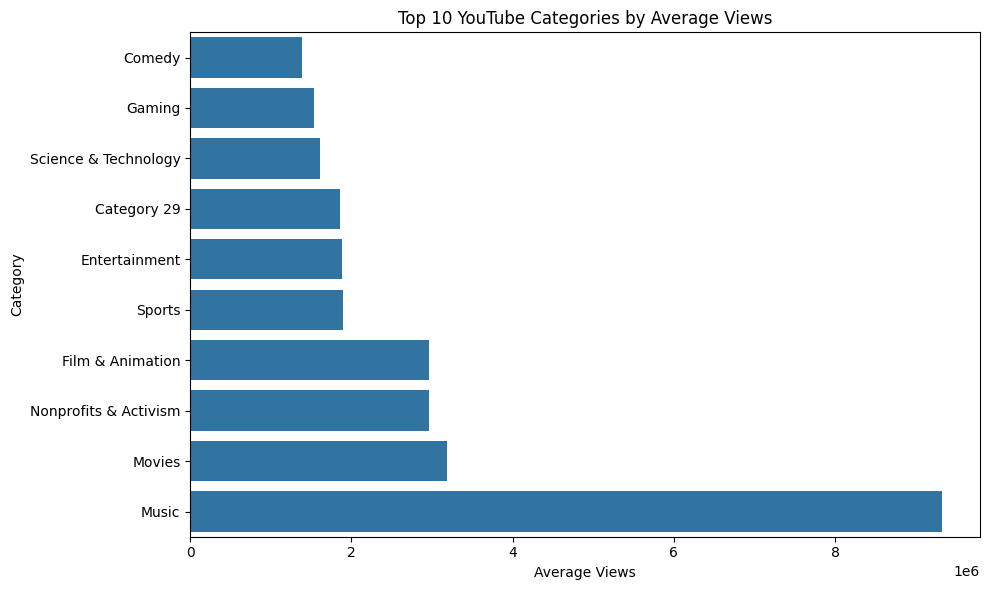

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

top_categories = category_analysis.head(10).sort_values(
    "average_views"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_categories,
    x="average_views",
    y="category"
)

plt.title("Top 10 YouTube Categories by Average Views")
plt.xlabel("Average Views")
plt.ylabel("Category")
plt.tight_layout()

plt.savefig(
    "top_categories.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
df_clean.to_csv(
    "cleaned_youtube_data.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [12]:
!pip -q install textblob

In [13]:
from textblob import TextBlob
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

print("Sentiment analysis libraries are ready!")

Sentiment analysis libraries are ready!


#Analyze sentiment of video titles

In [14]:
def analyze_sentiment(text):
    polarity = TextBlob(str(text)).sentiment.polarity

    if polarity > 0.05:
        return "Positive"
    elif polarity < -0.05:
        return "Negative"
    else:
        return "Neutral"

df_clean["title_sentiment"] = df_clean["title"].apply(
    analyze_sentiment
)

print("Title sentiment analysis completed!")

display(
    df_clean[
        ["title", "title_sentiment", "views", "region"]
    ].head(10)
)

Title sentiment analysis completed!


,title,title_sentiment,views,region
0,Sharry Mann: Cute Munda ( Song Teaser) | Parmi...,Positive,1096327,India
1,"पीरियड्स के समय, पेट पर पति करता ऐसा, देखकर दं...",Neutral,590101,India
2,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,Positive,473988,India
3,Eruma Saani | Tamil vs English,Neutral,1242680,India
4,why Samantha became EMOTIONAL @ Samantha naga ...,Neutral,464015,India
5,"MCA (Middle Class Abbayi) TEASER - Nani,Sai Pa...",Neutral,6106669,India
6,Daang ( Full Video ) | Mankirt Aulakh | Sukh S...,Positive,5718766,India
7,Padmavati : Ek Dil Ek Jaan Video Song | Deepik...,Neutral,10588371,India
8,Chiranjeevi in Naga Chaitanya - Samantha Recep...,Neutral,118223,India
9,New bike vs Old bike - the reality,Positive,969030,India


#Analyze sentiment of video tags

In [15]:
df_clean["tag_sentiment"] = df_clean["tags"].apply(
    analyze_sentiment
)

print("Tag sentiment analysis completed!")

display(
    df_clean[["tags", "tag_sentiment"]].head(10)
)

Tag sentiment analysis completed!


,tags,tag_sentiment
0,"sharry mann|""sharry mann new song""|""sharry man...",Positive
1,"पीरियड्स के समय|""पेट पर पति करता ऐसा""|""देखकर द...",Positive
2,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,Positive
3,"Eruma Saani|""Tamil Comedy Videos""|""Films""|""Mov...",Neutral
4,"Filmylooks|""latest news""|""telugu movies""|""telu...",Positive
5,"Nenu Local|""Nenu Local Telugu Movie""|""Nani""|""S...",Positive
6,"punjabi songs|""punjabi bhangra""|""punjabi music...",Positive
7,"Ek Dil Ek Jaan Video Song|""'Ek Dil Ek Jaan'""|""...",Positive
8,Chiranjeevi in Naga Chaitanya - Samantha Recep...,Positive
9,"Jump cuts|""Jumpcuts""|""Tamil comedy""|""Tamil Com...",Positive


#Create the sentiment distribution chart

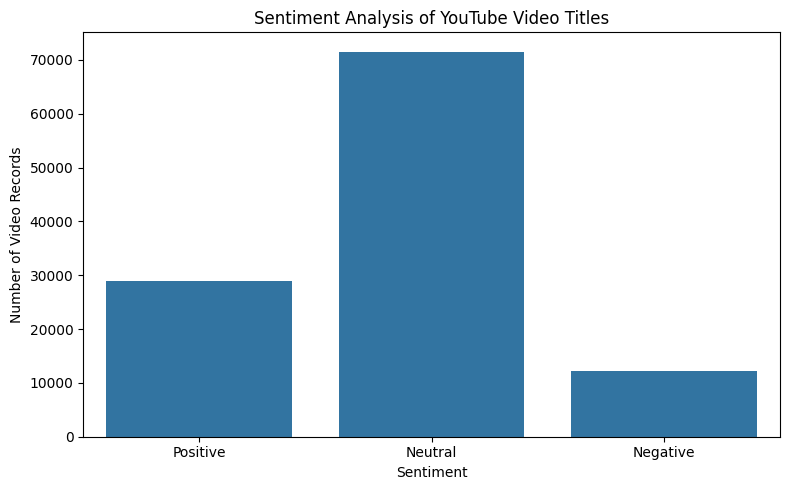

,Number of Records
title_sentiment,
Positive,28944
Neutral,71556
Negative,12235


In [16]:
sentiment_counts = (
    df_clean["title_sentiment"]
    .value_counts()
    .reindex(["Positive", "Neutral", "Negative"], fill_value=0)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

plt.title("Sentiment Analysis of YouTube Video Titles")
plt.xlabel("Sentiment")
plt.ylabel("Number of Video Records")

plt.tight_layout()
plt.savefig("title_sentiment.png", dpi=300, bbox_inches="tight")
plt.show()

display(sentiment_counts.to_frame("Number of Records"))

#Compare sentiment with average views

In [17]:
sentiment_views = (
    df_clean.groupby("title_sentiment")
    .agg(
        average_views=("views", "mean"),
        total_views=("views", "sum"),
        video_records=("video_id", "count")
    )
    .sort_values("average_views", ascending=False)
    .reset_index()
)

display(sentiment_views)

,title_sentiment,average_views,total_views,video_records
0,Negative,4.597714e+06,56253033274,12235
1,Neutral,3.388781e+06,242487602540,71556
2,Positive,2.066558e+06,59814467476,28944


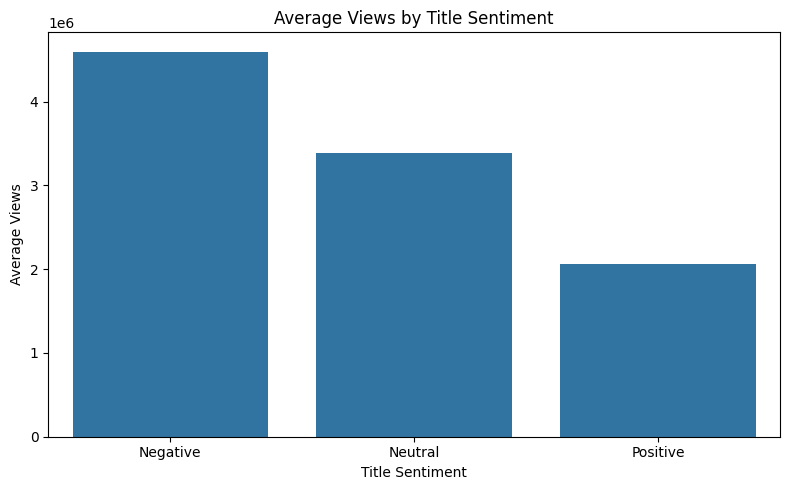

In [18]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=sentiment_views,
    x="title_sentiment",
    y="average_views"
)

plt.title("Average Views by Title Sentiment")
plt.xlabel("Title Sentiment")
plt.ylabel("Average Views")

plt.tight_layout()
plt.savefig("sentiment_vs_views.png", dpi=300, bbox_inches="tight")
plt.show()

#Save the sentiment results

In [19]:
df_clean.to_csv(
    "youtube_sentiment_results.csv",
    index=False
)

sentiment_views.to_csv(
    "sentiment_views_summary.csv",
    index=False
)

print("Sentiment results saved successfully!")

Sentiment results saved successfully!


#SQLite database

In [20]:
import sqlite3
import pandas as pd

# Create SQLite database
conn = sqlite3.connect("youtube_analytics.db")

# Store the cleaned dataset in a SQL table
df_clean.to_sql(
    "youtube_videos",
    conn,
    if_exists="replace",
    index=False
)

print("SQLite database created successfully!")
print("Table name: youtube_videos")

SQLite database created successfully!
Table name: youtube_videos


#Rank categories by average views using SQL

In [21]:
query = """
SELECT
    category,
    ROUND(AVG(views), 2) AS average_views,
    SUM(views) AS total_views,
    COUNT(*) AS video_records
FROM youtube_videos
GROUP BY category
ORDER BY average_views DESC
LIMIT 10;
"""

sql_results = pd.read_sql_query(query, conn)

display(sql_results)

,category,average_views,total_views,video_records
0,Music,9330494.85,218884078661,23459
1,Movies,3191953.00,31919530,10
2,Nonprofits & Activism,2963884.07,168941392,57
3,Film & Animation,2959951.40,18854890404,6370
4,Sports,1892349.77,8933783262,4721
5,Entertainment,1880824.68,63502283766,33763
6,Category 29,1861510.69,359271564,193
7,Science & Technology,1614866.90,5538993462,3430
8,Gaming,1535929.01,4068675945,2649
9,Comedy,1392457.83,11473852529,8240


In [22]:
sql_results.to_csv(
    "sql_category_ranking.csv",
    index=False
)

print("SQL category ranking saved!")

SQL category ranking saved!


#Compare countries using SQL

In [23]:
region_query = """
SELECT
    region,
    COUNT(*) AS video_records,
    ROUND(AVG(views), 2) AS average_views,
    SUM(likes) AS total_likes,
    SUM(comment_count) AS total_comments
FROM youtube_videos
GROUP BY region
ORDER BY average_views DESC;
"""

region_results = pd.read_sql_query(region_query, conn)

display(region_results)

,region,video_records,average_views,total_likes,total_comments
0,Great Britain,38745,5911292.65,5209935076,506799667
1,USA,40901,2360678.04,3037788204,345554845
2,India,33089,996342.51,846668793,83542368


In [24]:
region_results.to_csv(
    "sql_region_comparison.csv",
    index=False
)

#Region-wise comparison chart

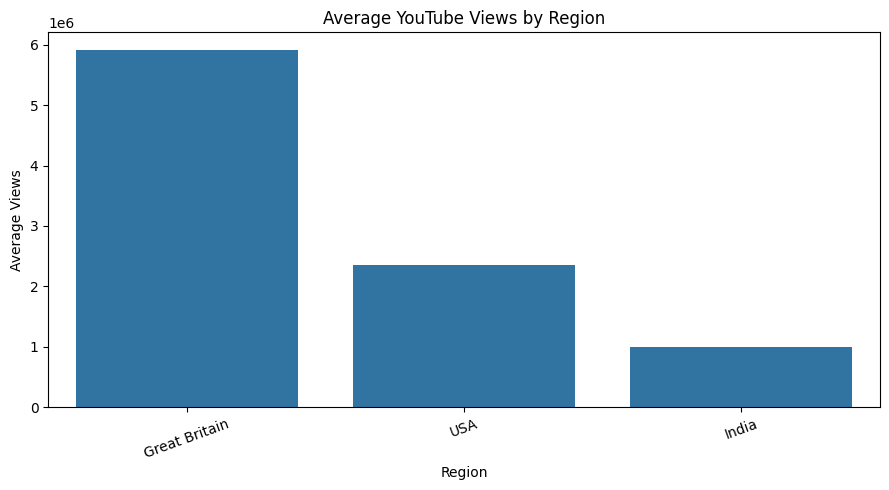

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=region_results,
    x="region",
    y="average_views"
)

plt.title("Average YouTube Views by Region")
plt.xlabel("Region")
plt.ylabel("Average Views")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    "region_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#Engagement across countries

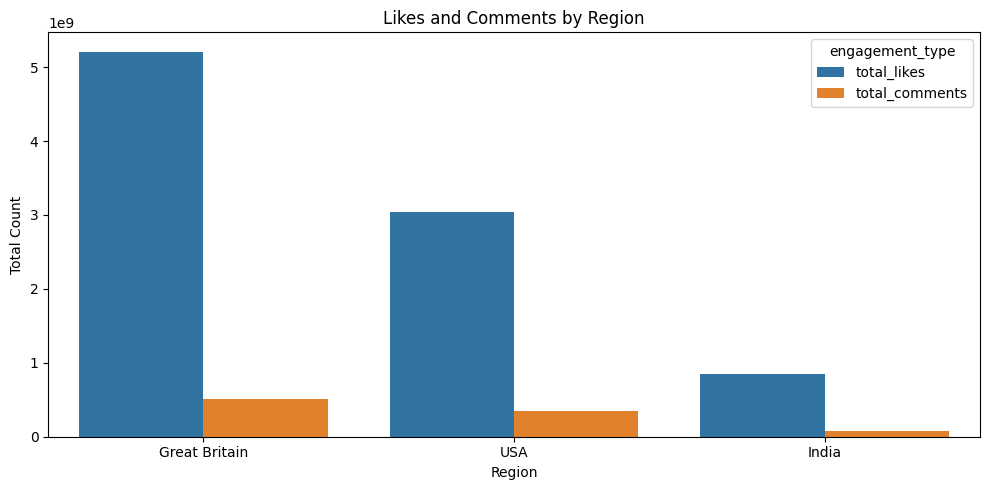

In [26]:
engagement = region_results.melt(
    id_vars="region",
    value_vars=["total_likes", "total_comments"],
    var_name="engagement_type",
    value_name="total_count"
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=engagement,
    x="region",
    y="total_count",
    hue="engagement_type"
)

plt.title("Likes and Comments by Region")
plt.xlabel("Region")
plt.ylabel("Total Count")
plt.tight_layout()

plt.savefig(
    "regional_engagement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
conn.close()

print("SQL analysis completed successfully!")
print("Saved files:")
print("- youtube_analytics.db")
print("- sql_category_ranking.csv")
print("- sql_region_comparison.csv")
print("- region_comparison.png")
print("- regional_engagement.png")

SQL analysis completed successfully!
Saved files:
- youtube_analytics.db
- sql_category_ranking.csv
- sql_region_comparison.csv
- region_comparison.png
- regional_engagement.png


#Analyze YouTube trending dates

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convert trending_date to datetime
df_clean["trending_date"] = pd.to_datetime(
    df_clean["trending_date"],
    errors="coerce",
    utc=True
)

# Remove records with invalid dates
time_data = df_clean.dropna(
    subset=["trending_date"]
).copy()

# Group records by date
daily_trends = (
    time_data.groupby(
        time_data["trending_date"].dt.date
    )
    .size()
    .reset_index(name="trending_records")
)

daily_trends.columns = ["trending_date", "trending_records"]

daily_trends["trending_date"] = pd.to_datetime(
    daily_trends["trending_date"]
)

display(daily_trends.head())
print("Number of dates analyzed:", len(daily_trends))

,trending_date,trending_records
0,2001-01-18,594
1,2001-02-18,588
2,2001-03-18,592
3,2001-04-18,586
4,2001-05-18,579


Number of dates analyzed: 77


#Time-series chart

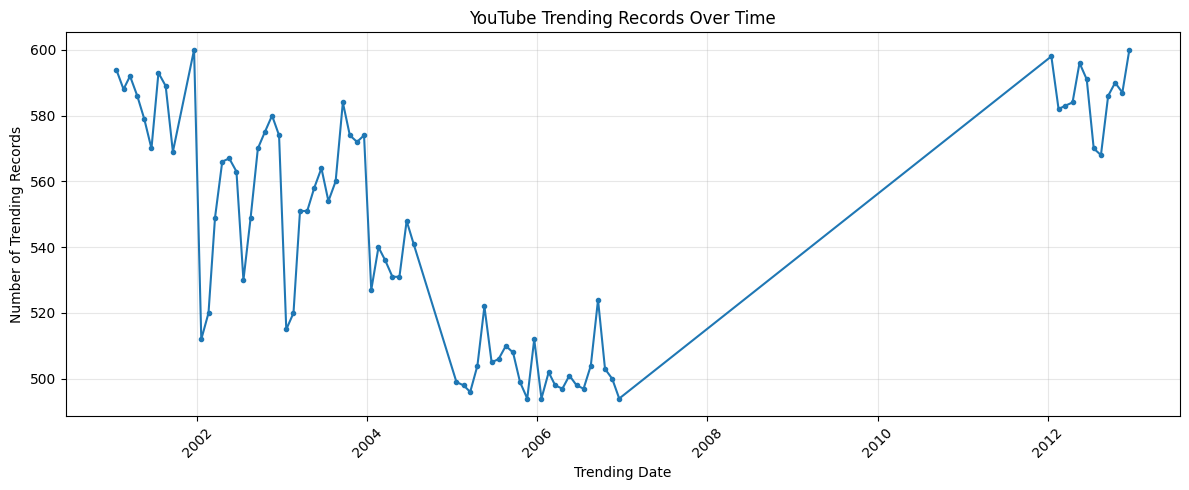

In [29]:
plt.figure(figsize=(12, 5))

plt.plot(
    daily_trends["trending_date"],
    daily_trends["trending_records"],
    marker="o",
    markersize=3
)

plt.title("YouTube Trending Records Over Time")
plt.xlabel("Trending Date")
plt.ylabel("Number of Trending Records")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "trending_over_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#Analyze how long videos remain trending

In [30]:
video_duration = (
    time_data.dropna(subset=["video_id"])
    .groupby(["region", "video_id"])
    .agg(
        trending_days=("trending_date", "nunique"),
        first_trending_date=("trending_date", "min"),
        last_trending_date=("trending_date", "max")
    )
    .reset_index()
)

display(
    video_duration.sort_values(
        "trending_days", ascending=False
    ).head(10)
)

video_duration.to_csv(
    "trending_duration.csv",
    index=False
)

print("Trending duration analysis completed!")

,region,video_id,trending_days,first_trending_date,last_trending_date
2233,India,#NAME?,73,2001-01-18 00:00:00+00:00,2012-12-17 00:00:00+00:00
862,Great Britain,NooW_RbfdWI,20,2002-05-18 00:00:00+00:00,2003-12-18 00:00:00+00:00
410,Great Britain,BhIEIO0vaBE,20,2002-05-18 00:00:00+00:00,2003-12-18 00:00:00+00:00
116,Great Britain,2z3EUY1aXdY,20,2002-05-18 00:00:00+00:00,2003-12-18 00:00:00+00:00
1392,Great Britain,baj6llvgpWA,19,2002-03-18 00:00:00+00:00,2003-09-18 00:00:00+00:00
2013,Great Britain,tEnCoocmPQM,19,2002-03-18 00:00:00+00:00,2003-09-18 00:00:00+00:00
1451,Great Britain,dARAN1z2KqY,18,2005-04-18 00:00:00+00:00,2006-09-18 00:00:00+00:00
439,Great Britain,CX11yw6YL1w,18,2005-04-18 00:00:00+00:00,2006-09-18 00:00:00+00:00
1894,Great Britain,pisY6J2Ky6U,18,2002-04-18 00:00:00+00:00,2003-09-18 00:00:00+00:00
2119,Great Britain,wbSwFU6tY1c,18,2002-07-18 00:00:00+00:00,2003-12-18 00:00:00+00:00


Trending duration analysis completed!


In [31]:
!pip -q install reportlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 12.5 MB/s eta 0:00:00


In [32]:
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.pagesizes import A4
from reportlab.lib.units import inch
from google.colab import files

report_path = "YouTube_Trending_Analytics_Report.pdf"

doc = SimpleDocTemplate(
    report_path,
    pagesize=A4,
    rightMargin=0.55 * inch,
    leftMargin=0.55 * inch,
    topMargin=0.4 * inch,
    bottomMargin=0.4 * inch
)

styles = getSampleStyleSheet()

styles.add(ParagraphStyle(
    name="ProjectTitle",
    parent=styles["Title"],
    fontSize=16,
    leading=19,
    alignment=TA_CENTER,
    spaceAfter=8
))

styles.add(ParagraphStyle(
    name="ProjectBody",
    parent=styles["BodyText"],
    fontSize=8.5,
    leading=11,
    spaceAfter=5
))

story = []

story.append(Paragraph(
    "YouTube Trending Video Analytics",
    styles["ProjectTitle"]
))

story.append(Paragraph(
    "<b>1. Introduction</b><br/>"
    "YouTube trending videos provide useful information about content "
    "popularity and audience engagement. This project analyzes trending "
    "video records across India, the USA, and Great Britain to identify "
    "category popularity, sentiment patterns, and regional differences.",
    styles["ProjectBody"]
))

story.append(Paragraph(
    "<b>2. Abstract</b><br/>"
    "The project uses Python, SQL, and data visualization to study "
    "YouTube trending video datasets. The data is cleaned and standardized, "
    "titles and tags are classified by estimated sentiment, categories are "
    "ranked by average views, and regional and time-based patterns are "
    "visualized.",
    styles["ProjectBody"]
))

story.append(Paragraph(
    "<b>3. Tools Used</b><br/>"
    "Google Colab, Python, Pandas, NumPy, Matplotlib, Seaborn, "
    "TextBlob, SQLite, SQL, and ReportLab. Tableau can be used to "
    "create an additional interactive dashboard.",
    styles["ProjectBody"]
))

story.append(Paragraph(
    "<b>4. Steps Involved in Building the Project</b>",
    styles["ProjectBody"]
))

table_data = [
    ["Step", "Description"],
    ["Data collection", "Downloaded country-wise video CSV and category JSON files from Kaggle."],
    ["Data cleaning", "Handled missing values, standardized fields, and removed duplicate records."],
    ["Sentiment analysis", "Classified video titles and tags as positive, neutral, or negative."],
    ["SQL analysis", "Ranked categories by average views and compared regional engagement."],
    ["Visualization", "Created category, sentiment, regional, and time-series charts."],
    ["Reporting", "Exported the analysis results and generated the final PDF report."]
]

table = Table(
    table_data,
    colWidths=[1.25 * inch, 5.45 * inch],
    repeatRows=1
)

table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#5146D8")),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
    ("FONTSIZE", (0, 0), (-1, -1), 8),
    ("LEADING", (0, 0), (-1, -1), 10),
    ("GRID", (0, 0), (-1, -1), 0.4, colors.lightgrey),
    ("VALIGN", (0, 0), (-1, -1), "TOP"),
    ("LEFTPADDING", (0, 0), (-1, -1), 5),
    ("RIGHTPADDING", (0, 0), (-1, -1), 5),
    ("TOPPADDING", (0, 0), (-1, -1), 4),
    ("BOTTOMPADDING", (0, 0), (-1, -1), 4),
]))

story.append(table)
story.append(Spacer(1, 7))

story.append(Paragraph(
    "<b>5. Conclusion</b><br/>"
    f"The cleaned dataset contains {len(df_clean):,} records from "
    f"{df_clean['region'].nunique()} regions. SQL queries and visualizations "
    "provide a way to compare category popularity, estimated sentiment, "
    "regional engagement, and trending activity over time. Findings depend "
    "on the available dataset and its limitations.",
    styles["ProjectBody"]
))

doc.build(story)

print("PDF report generated successfully!")
files.download(report_path)

PDF report generated successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
import os
import shutil
from google.colab import files

output_dir = "youtube_project_outputs"
os.makedirs(output_dir, exist_ok=True)

# Files created during the project
project_files = [
    "cleaned_youtube_data.csv",
    "youtube_sentiment_results.csv",
    "sentiment_views_summary.csv",
    "sql_category_ranking.csv",
    "sql_region_comparison.csv",
    "region_comparison.png",
    "regional_engagement.png",
    "top_categories.png",
    "title_sentiment.png",
    "sentiment_vs_views.png",
    "trending_over_time.png",
    "trending_duration.csv",
    "YouTube_Trending_Analytics_Report.pdf",
    "youtube_analytics.db"
]

for filename in project_files:
    if os.path.exists(filename):
        shutil.copy(filename, output_dir)

zip_path = shutil.make_archive(
    "/content/YouTube_Trending_Analytics_Project",
    "zip",
    output_dir
)

files.download(zip_path)

print("Project ZIP file prepared!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Project ZIP file prepared!
